# Manual EDA and checks

In [8]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Features for synthetic simulations tuned to real dataset

In [9]:
ROOT = Path(".")
BEH_MAP = {
    "traveling": "traveling",
    "milling": "milling",
    "shoaling": "shoaling",
    "expansion": "expansion",
    "compaction": "compaction",
}
FEAT_MAP = {
    "phi_trans": "phi_trans",
    "phi_tan": "phi_tan",
    "phi_rad_pm": "phi_rad",
    "phi_local": "phi_local",
}
BEHAVIOR_ORDER = ["traveling", "milling", "shoaling", "expansion", "compaction"]


def _rows_from_features(features_by_behavior: dict, dataset: str, behavior_map: dict | None = None) -> list[dict]:
    rows = []
    mapping = BEH_MAP if behavior_map is None else behavior_map
    for canon, short in mapping.items():
        block = features_by_behavior.get(canon, {})
        feats = block.get("features", block)
        for json_name, plot_name in FEAT_MAP.items():
            stats = feats.get(json_name) or feats.get(f"{json_name}_mean", {})
            rows.append(
                {
                    "behavior": short,
                    "dataset": dataset,
                    "feature": plot_name,
                    "feature mean": float(stats.get("mean", float("nan"))),
                    "feature std": float(stats.get("std", float("nan"))),
                }
            )
    return rows


with open(ROOT / "results" / "calibration_report.json", encoding="utf-8") as f:
    couzin = json.load(f)
with open(ROOT / "results" / "tuning" / "feature_match" / "best.json", encoding="utf-8") as f:
    tuned = json.load(f)

rows = []
rows.extend(_rows_from_features(tuned["sim_features"], "Synthetic dataset"))
rows.extend(_rows_from_features(couzin, "CouzinLab dataset"))
calib_data = pd.DataFrame(rows)

In [10]:
level_order = ["phi_trans", "phi_tan", "phi_rad", "phi_local"]
feature_order = level_order
hue_order = ["Synthetic dataset", "CouzinLab dataset"]
feature_labels = {
    "phi_trans": r"$\Phi_{\mathrm{trans}}$",
    "phi_tan": r"$\Phi_{\mathrm{tan}}$",
    "phi_rad": r"$\Phi_{\mathrm{rad}}^{\pm}$",
    "phi_local": r"$\Phi_{\mathrm{local}}$",
}

In [11]:
behavior_order = [b for b in BEHAVIOR_ORDER if b in set(calib_data["behavior"])]
colors = ['#E5943D','#7DC4BE']

/tmp/ipykernel_1974498/3589313336.py:2: RuntimeWarning: All-NaN axis encountered
  rate_span = np.nanmax(np.abs(rate_rows["feature mean"]) + rate_rows["feature std"])


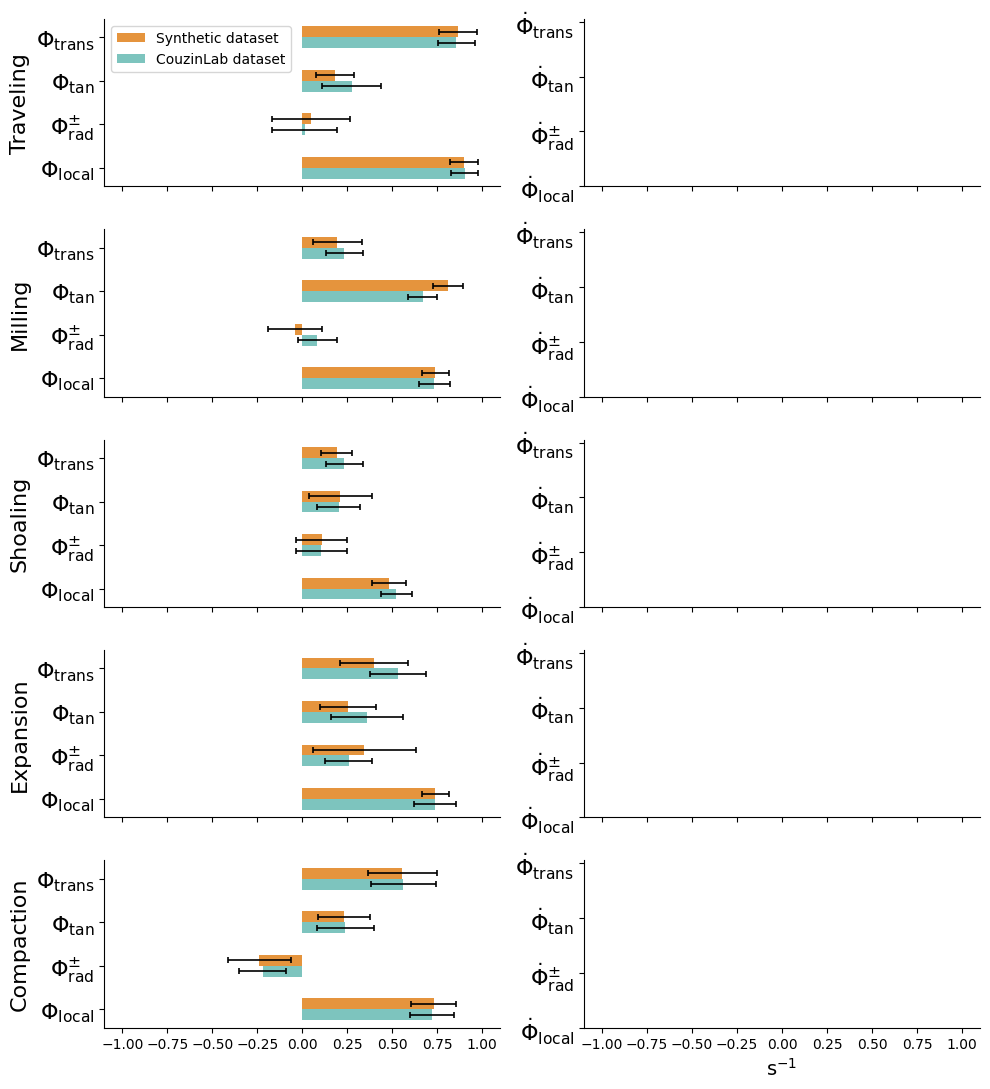

In [12]:
panels = [
    (level_order, (-1.1, 1.1), ""),
]

fig, axes = plt.subplots(
    len(behavior_order),
    len(panels),
    figsize=(6, 2.2 * len(behavior_order)),
    sharex="col",
    squeeze=False,
)

def plot_behavior(behavior: str, axis_id: int, features: list[str], xlim: tuple[float, float], ax, data=None):
    if data is None:
        data = calib_data
    d = data[data["behavior"] == behavior].copy()

    y = np.arange(len(features))
    bar_height = 0.25
    offsets = (np.arange(len(hue_order)) - (len(hue_order) - 1) / 2) * bar_height

    for i, dataset in enumerate(hue_order):
        sub = (
            d[d["dataset"] == dataset]
            .set_index("feature")
            .reindex(features)
        )
        means = sub["feature mean"].to_numpy(dtype=float)
        stds = sub["feature std"].to_numpy(dtype=float)
        positions = y + offsets[i]
        valid = ~np.isnan(means)
        ax.barh(
            positions[valid],
            means[valid],
            height=bar_height,
            xerr=stds[valid],
            capsize=2,
            color=colors[i],
            label=dataset,
            error_kw={"elinewidth": 1.2, "capthick": 1.2},
        )

    ax.set_yticks(y)
    ax.set_yticklabels([feature_labels[f] for f in features], fontsize=16)
    ax.invert_yaxis()
    ax.set_xlim(*xlim)
    ax.set_xlabel("")
    if axis_id == 0 and features is level_order:
        ax.legend(frameon=True)


for axis_id, behavior in enumerate(behavior_order):
    axes[axis_id, 0].set_ylabel(behavior.capitalize(), fontsize=16)
    for col, (features, xlim, _unit) in enumerate(panels):
        plot_behavior(
            behavior=behavior,
            axis_id=axis_id,
            features=features,
            xlim=xlim,
            ax=axes[axis_id, col],
        )

for col, (_features, _xlim, unit) in enumerate(panels):
    axes[-1, col].set_xlabel(unit, fontsize=14)

sns.despine()
plt.tight_layout()
plt.savefig("results/behavior_bars.png", dpi=300)
plt.show()


## Transient states

In [13]:
from collections import defaultdict

from joblib import Parallel, delayed

from scripts.calibrate_baselines import _aggregate
from src.features.dataset import features_from_sim_entry, load_manifest
from src.labels import TRANSITIONS


def _transition_label(label: str) -> str:
    left, right = label.split("_to_", 1)
    return f"{left} \u2192 {right}"


def _transition_windows(entries: list[dict]) -> dict[str, list]:
    grouped = defaultdict(list)
    sim_root = ROOT / "sim_datasets"
    for entry in entries:
        for vec, label in features_from_sim_entry(entry, mode="windows", sim_root=sim_root):
            grouped[label].append(vec)
    return grouped


manifest_path = ROOT / "sim_datasets" / "manifest.json"
sim_trans = {}
if manifest_path.exists():
    manifest = load_manifest(manifest_path)
    transition_entries = [
        entry for entry in manifest
        if entry.get("behavior") in TRANSITIONS and entry.get("valid", True)
    ]
    chunk = 250
    batches = [transition_entries[i:i + chunk] for i in range(0, len(transition_entries), chunk)]
    parts = Parallel(n_jobs=-1)(delayed(_transition_windows)(batch) for batch in batches)
    sim_rows = defaultdict(list)
    for part in parts:
        for label, vecs in part.items():
            sim_rows[label].extend(vecs)
    sim_trans = _aggregate(sim_rows)

present = [label for label in TRANSITIONS if label in couzin or label in sim_trans]
trans_map = {label: _transition_label(label) for label in present}
trans_rows = []
trans_rows.extend(_rows_from_features(sim_trans, "Synthetic dataset", trans_map))
trans_rows.extend(_rows_from_features(couzin, "CouzinLab dataset", trans_map))
trans_data = pd.DataFrame(trans_rows)
trans_order = [trans_map[label] for label in present if label in set(trans_data["behavior"]) or trans_map[label] in set(trans_data["behavior"])]


In [ ]:
trans_panels = [
    (level_order, (-1.1, 1.1), ""),
]

fig, axes = plt.subplots(
    len(trans_order),
    len(trans_panels),
    figsize=(6, 2.2 * len(trans_order)),
    sharex="col",
    squeeze=False,
)

for axis_id, behavior in enumerate(trans_order):
    axes[axis_id, 0].set_ylabel(behavior, fontsize=12)
    for col, (features, xlim, _unit) in enumerate(trans_panels):
        plot_behavior(
            behavior=behavior,
            axis_id=axis_id,
            features=features,
            xlim=xlim,
            ax=axes[axis_id, col],
            data=trans_data,
        )

for col, (_features, _xlim, unit) in enumerate(trans_panels):
    axes[-1, col].set_xlabel(unit, fontsize=14)

sns.despine()
plt.tight_layout()
plt.savefig("results/behavior_bars_transitions.png", dpi=300)
plt.show()
